# Module 2 · The Night Line: Sequences
**Verse 2 + pre-chorus "MEMORY" + chorus 2 "GONE" · 1:00–1:59**

Images have a fixed size. Text, audio and code are **sequences** of varying length, where order matters. Verse 2 is a night train: each car is one sung word, and four generations of machinery ride along it. You'll build each of them and score them all on the same held-out text:

n-gram counting → RNN (and why it forgets) → LSTM gates → seq2seq's bottleneck → attention → the Transformer → encoder vs decoder (BERT vs GPT) → the parts that changed between 2017 and today's LLMs.

It builds on Module 0's classification loss (predicting the next character is a 65-way classification) and its tensor shapes: text batches are (B, T) integers, and (B, T, C) once embedded.

**Runtime:** about 4–5 minutes on the `laptop` tier on CPU, plus a 260 MB DistilBERT download in §2.7.



In [1]:
import sys; sys.path.insert(0, '.')
from blcourse import *
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
hardware_report()



python 3.11.15 · torch 2.15.0 · arm64 · 64 GB RAM
DEVICE = 'mps'   TIER = 'laptop'   (override: BASELINE_TIER / BASELINE_DEVICE)


## 2.1 Tokens: turning text into integers
Models consume numbers, so text is first split into **tokens**, each mapped to an integer ID. Our own models will use the simplest tokenizer, one token per character. Production LLMs use **byte-pair encoding (BPE)**, which merges frequent character runs into sub-word tokens. Here's how a real LLM tokenizer sees the chorus line (the first run downloads a few MB):



In [2]:
from transformers import AutoTokenizer
llm_tok = AutoTokenizer.from_pretrained(CFG['llm'])
line = "You were state of the art, now you're just a baseline."
ids = llm_tok.encode(line)
print(len(line), 'characters →', len(ids), 'BPE tokens')
print(' | '.join(llm_tok.decode([i]) for i in ids))
print(ids)



54 characters → 14 BPE tokens
You |  were |  state |  of |  the |  art | , |  now |  you | 're |  just |  a |  baseline | .
[2610, 1033, 1584, 315, 279, 1947, 11, 1431, 498, 2299, 1101, 264, 25869, 13]


Our corpus is *Tiny Shakespeare* (about 1 MB of public-domain plays). We hold out the last 10% as the **validation** set, and every model in this module is scored on it in the same unit: **<abbr title="Minus the log of the probability the model gave to the right answer, averaged.">cross-entropy</abbr> in <abbr title="A unit for measuring surprise, like bits but using the natural log: 1 nat ≈ 1.44 bits.">nats</abbr> per character**. Lower is better.

*What's a nat?* It's a unit of surprise, like a bit but using the natural log (1 nat ≈ 1.44 bits). A loss of L nats means the model is about as unsure as if it were choosing among e<sup>L</sup> equally likely characters. That number, e<sup>L</sup>, is called the **perplexity**. Random guessing among the vocabulary scores ln(vocab size).



In [3]:
text = shakespeare()
data = CharData(text)
print(f'{len(text):,} chars · vocab {data.vocab} · random-guess loss ln({data.vocab}) = {math.log(data.vocab):.2f} nats/char')
print(text[:250])
SCORES = {}      # model name -> validation loss; we fill this in as we go



1,000,000 chars · vocab 65 · random-guess loss ln(65) = 4.17 nats/char
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



## 2.2 N-gram counting: a window three tokens wide



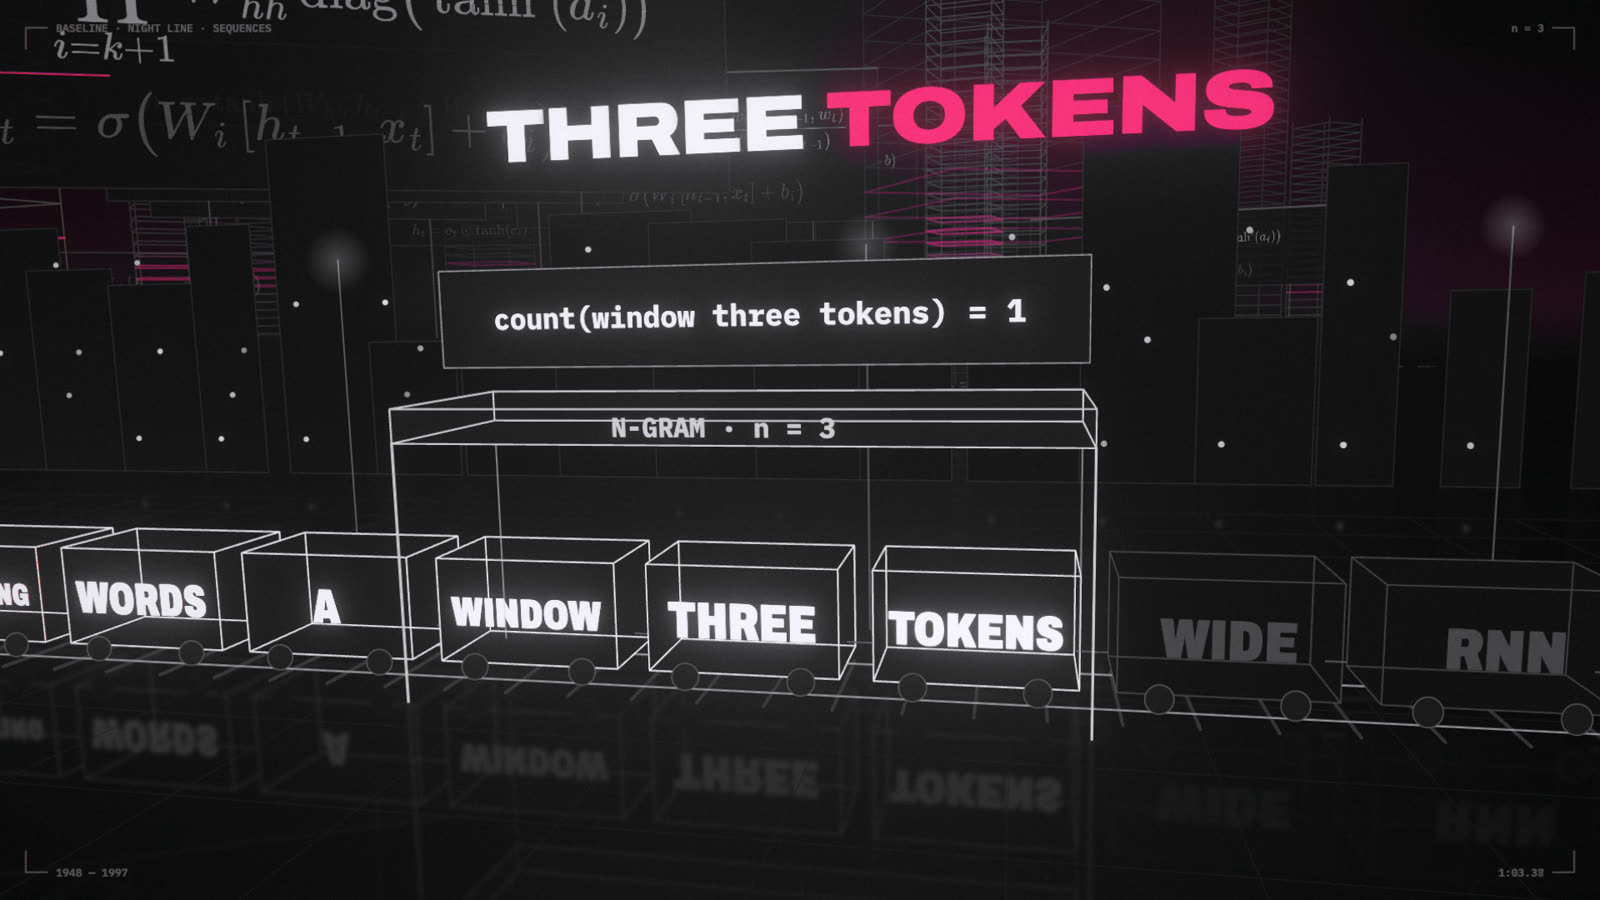

In [4]:
still(63.38)



The oldest language model is a lookup table. Count how often each character follows each context of n−1 characters, then predict by those frequencies:

$$P(c \mid \text{ctx}) = \frac{\text{count}(\text{ctx}, c) + k}{\text{count}(\text{ctx}) + kV}$$

The `+ k` (**smoothing**) keeps unseen combinations from getting probability zero, which would make the loss infinite.



In [5]:
train_txt = data.decode(data.train.tolist()); val_txt = data.decode(data.val[:100_000].tolist())

def ngram_loss(n, k=0.05):
    counts = defaultdict(Counter)
    for i in range(n - 1, len(train_txt)):
        counts[train_txt[i - n + 1:i]][train_txt[i]] += 1
    V, nll = data.vocab, 0.0
    for i in range(n - 1, len(val_txt)):
        c = counts.get(val_txt[i - n + 1:i])
        num = (c[val_txt[i]] if c else 0) + k
        den = (sum(c.values()) if c else 0) + k * V
        nll -= math.log(num / den)
    return nll / (len(val_txt) - n + 1), len(counts)

for n in range(1, 7):
    loss, ctxs = ngram_loss(n)
    SCORES[f'{n}-gram'] = loss
    print(f'{n}-gram: val {loss:.3f} nats/char   ({ctxs:,} distinct contexts)')



1-gram: val 3.308 nats/char   (1 distinct contexts)
2-gram: val 2.498 nats/char   (65 distinct contexts)


3-gram: val 2.023 nats/char   (1,361 distinct contexts)


4-gram: val 1.727 nats/char   (10,913 distinct contexts)


5-gram: val 1.720 nats/char   (46,346 distinct contexts)


6-gram: val 1.965 nats/char   (125,746 distinct contexts)


A longer window helps up to a point. After that the table becomes too **sparse**: most long contexts in the validation text never appeared in training, so the counts carry no information. Counting can't generalize from "the king" to "the queen". A model that represents tokens as vectors of numbers (**embeddings**) can, because similar tokens end up with similar vectors.



## 2.3 RNN: carry a hidden state, and backprop through time



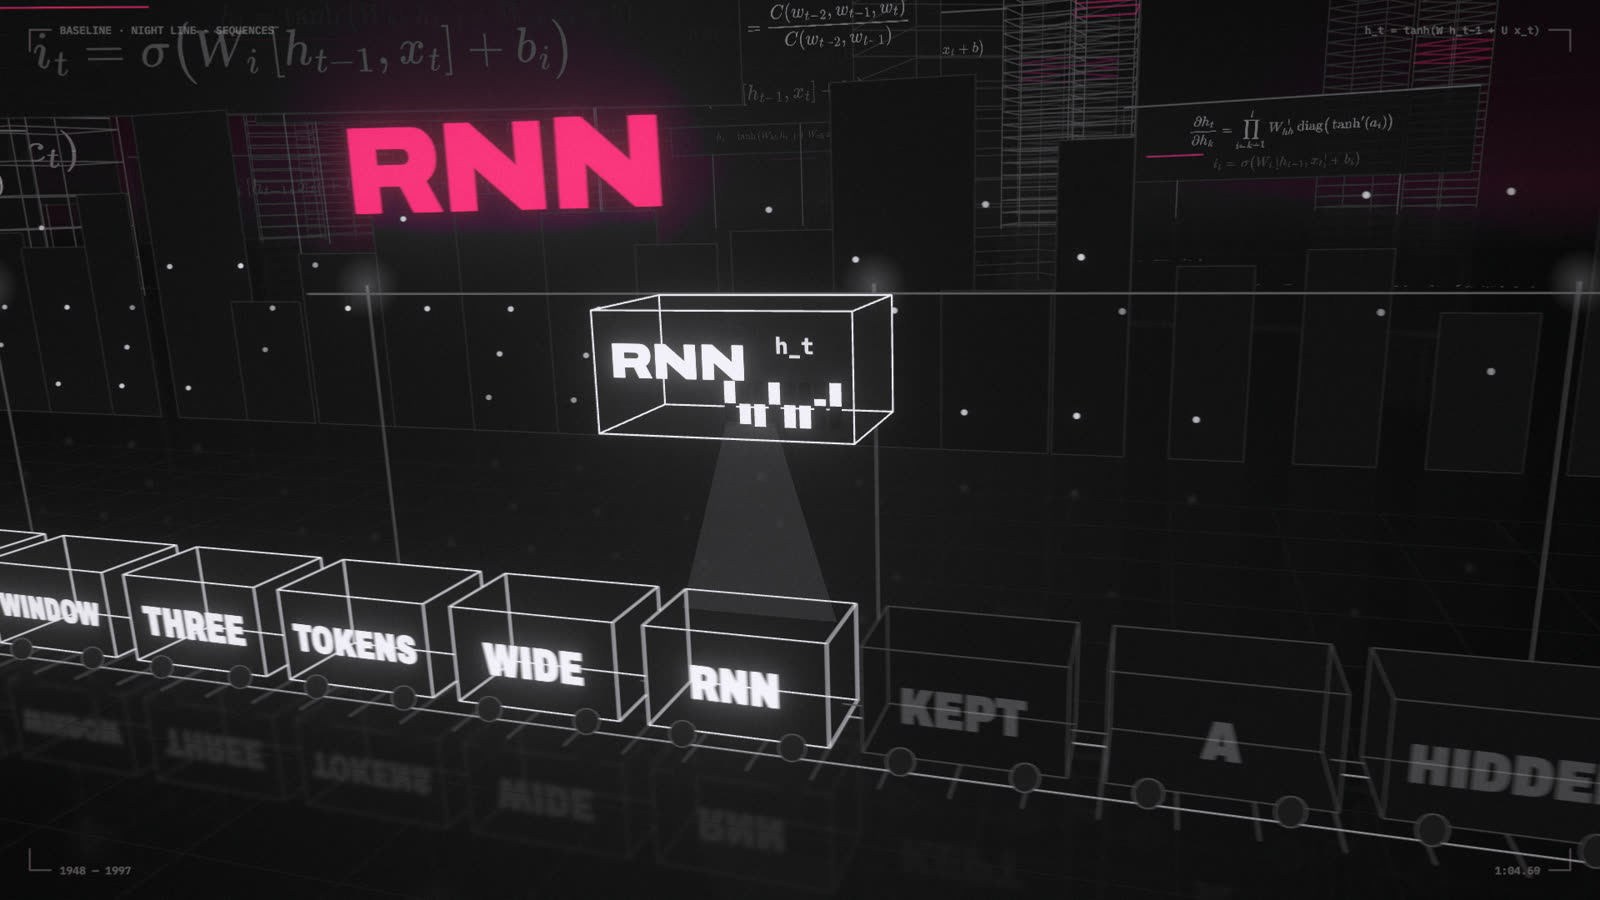

In [6]:
still(64.6)



A **recurrent neural network** reads one token at a time and updates a fixed-size vector, the **hidden state**:

$$h_t = \tanh(W_{hh}\,h_{t-1} + W_{xh}\,x_t + b)$$

In principle h carries everything seen so far. To train it, you unroll it over the sequence and backprop through the unrolled graph (**backprop through time**, BPTT). The gradient that reaches step t from step T has passed through W_hh about T − t times, so it gets multiplied by roughly the same matrix over and over. If W_hh's largest stretch factor (its spectral radius ρ) is below 1, the gradient **vanishes**. Above 1, it can **explode**.



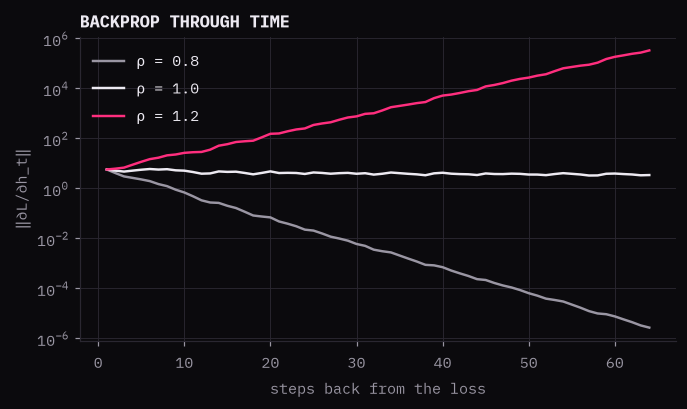

In [7]:
def bptt_profile(rho, T=64, d=32):
    seed(0)
    W = torch.randn(d, d); W *= rho / torch.linalg.eigvals(W).abs().max()
    hs, h = [], torch.zeros(d, requires_grad=True)
    for t in range(T):
        h = W @ h + 0.1 * torch.randn(d)        # linear RNN: the cleanest view of the effect
        h.retain_grad(); hs.append(h)
    hs[-1].sum().backward()
    return [x.grad.norm().item() for x in hs]

fig, ax = plt.subplots()
for rho, c in ((0.8, ASH), (1.0, BONE), (1.2, MAG)):
    ax.plot(range(64, 0, -1), bptt_profile(rho), c=c, label=f'ρ = {rho}')
ax.set(yscale='log', xlabel='steps back from the loss', ylabel='‖∂L/∂h_t‖', title='BACKPROP THROUGH TIME'); ax.legend();



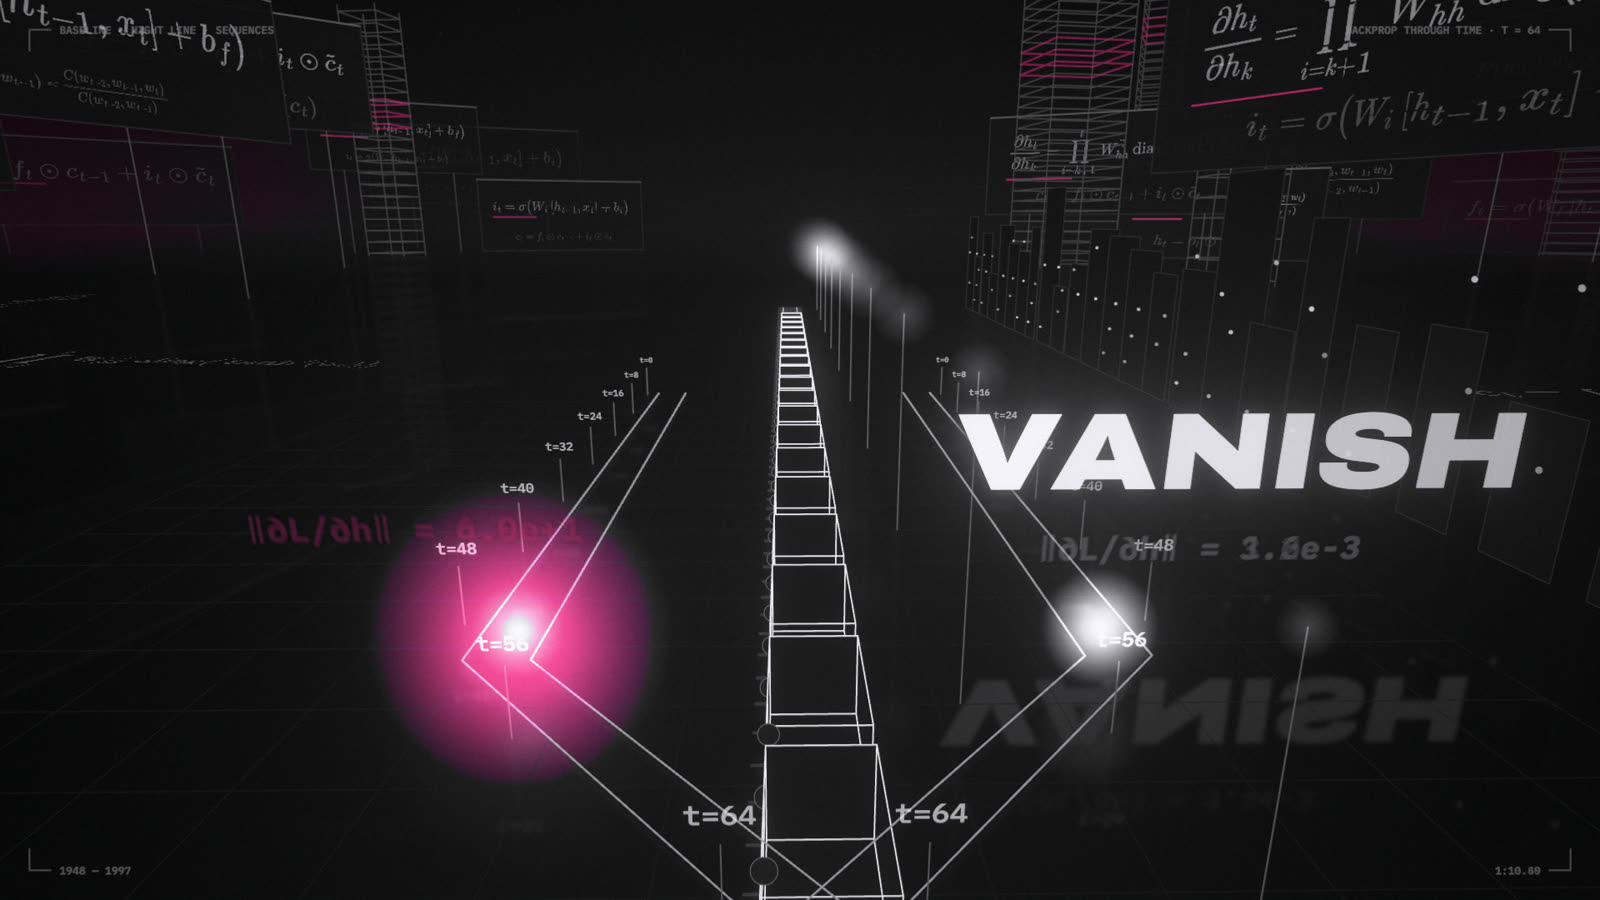

In [8]:
still(70.5)



Exploding gradients are easy to fix: **clip** the gradient norm (`clip_grad_norm_`, which every training loop in this course uses). Vanishing gradients are harder. They mean a plain RNN can't learn dependencies more than a few dozen steps long.



## 2.4 LSTM: put gates along the road (1997)
The LSTM keeps a separate **cell state** c that runs alongside the sequence like a highway, and three learned **gates** (values between 0 and 1) decide what happens to it at each step:

- **forget** f: how much of the old cell state to keep,
- **input** i: how much new information to write,
- **output** o: how much of the cell to reveal as the hidden state.

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t \qquad h_t = o_t \odot \tanh(c_t)$$

Because c is updated by *multiplying by f and adding*, rather than by being squashed through a matrix every step, the gradient along it can survive for hundreds of steps whenever f ≈ 1.



In [9]:
class CharLSTM(nn.Module):
    def __init__(self, vocab, hidden):
        super().__init__()
        self.emb = nn.Embedding(vocab, 64)
        self.lstm = nn.LSTM(64, hidden, batch_first=True)
        self.head = nn.Linear(hidden, vocab)
    def forward(self, idx, targets=None):
        h, _ = self.lstm(self.emb(idx))
        logits = self.head(h)
        return logits, None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())

L = CFG['lstm']
seed(0); lstm = CharLSTM(data.vocab, L['hidden'])
print(f'LSTM: {n_params(lstm):,} parameters')
lstm_hist = train_lm(lstm, data, L['steps'], L['block'], L['batch'], lr=4e-3, label='LSTM')
SCORES['LSTM'] = eval_loss(lstm, data, L['block'], iters=50)['val']



LSTM: 350,593 parameters


LSTM step   250  train 1.775  val 1.853  (5s)


LSTM step   500  train 1.543  val 1.657  (10s)


LSTM step   750  train 1.469  val 1.602  (15s)


LSTM step  1000  train 1.415  val 1.551  (20s)


LSTM step  1250  train 1.393  val 1.546  (25s)


LSTM step  1500  train 1.396  val 1.538  (29s)


**Watch the two columns.** Train loss keeps falling. On the bigger tiers, validation loss bottoms out and then rises: the model has started memorizing Tiny Shakespeare (only about 1 MB) instead of learning patterns that transfer. That's Module 0's overfitting curve, live. `train_lm` keeps the weights from the checkpoint with the lowest validation loss and restores them at the end. That's **early stopping**, the validation set doing the job Module 0 gave it. The bigger tiers also use **dropout**, which randomly zeroes some activations during training so no single path can memorize.

### Look at the gates
`nn.LSTM` doesn't return its gates, but they're just a function of its weights, so we can recompute them for a line of text. Each row below is one gate unit, each column one character.



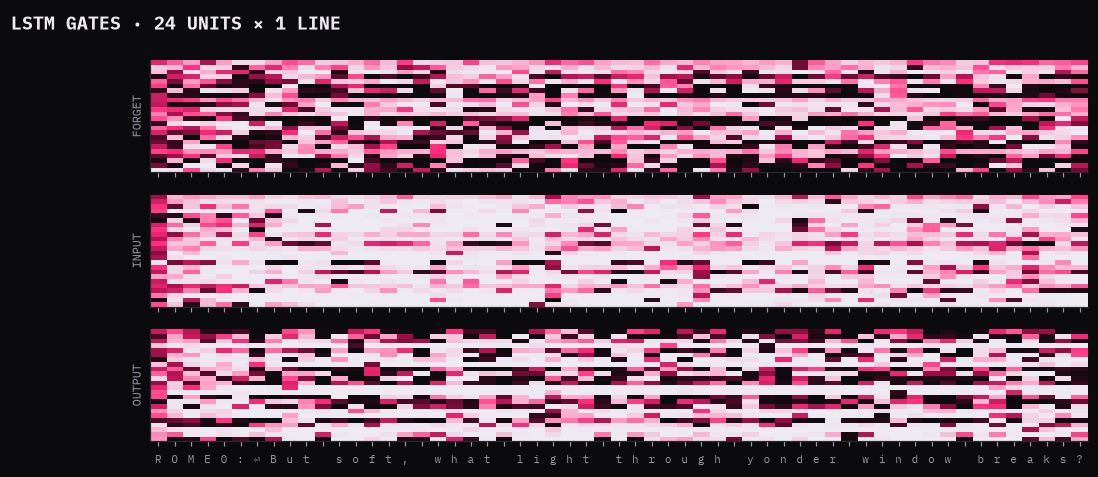

In [10]:
@torch.no_grad()
def lstm_gates(model, s):
    W_ih, W_hh = model.lstm.weight_ih_l0.cpu(), model.lstm.weight_hh_l0.cpu()
    b = (model.lstm.bias_ih_l0 + model.lstm.bias_hh_l0).cpu()
    x = model.emb.cpu()(torch.tensor(data.encode(s))); model.to(DEVICE)
    H = W_hh.shape[1]; h = c = torch.zeros(H); out = {k: [] for k in 'fio'}
    for xt in x:
        z = W_ih @ xt + W_hh @ h + b
        i, f, g, o = torch.sigmoid(z[:H]), torch.sigmoid(z[H:2*H]), torch.tanh(z[2*H:3*H]), torch.sigmoid(z[3*H:])
        c = f * c + i * g; h = o * torch.tanh(c)
        for k, v in zip('fio', (f, i, o)): out[k].append(v)
    return {k: torch.stack(v).T for k, v in out.items()}

s = 'ROMEO:\nBut soft, what light through yonder window breaks?'
g = lstm_gates(lstm, s)
fig, axes = plt.subplots(3, 1, figsize=(11, 4.5), sharex=True)
for ax, k, name in zip(axes, 'fio', ('FORGET', 'INPUT', 'OUTPUT')):
    ax.imshow(g[k][:24], aspect='auto', vmin=0, vmax=1, cmap='baseline'); ax.set_ylabel(name, fontsize=8); ax.set_yticks([]); ax.grid(False)
axes[-1].set_xticks(range(len(s))); axes[-1].set_xticklabels([c if c != '\n' else '⏎' for c in s], fontsize=7)
fig.suptitle('LSTM GATES · 24 UNITS × 1 LINE', x=0.01, ha='left', color=BONE, fontweight='bold');



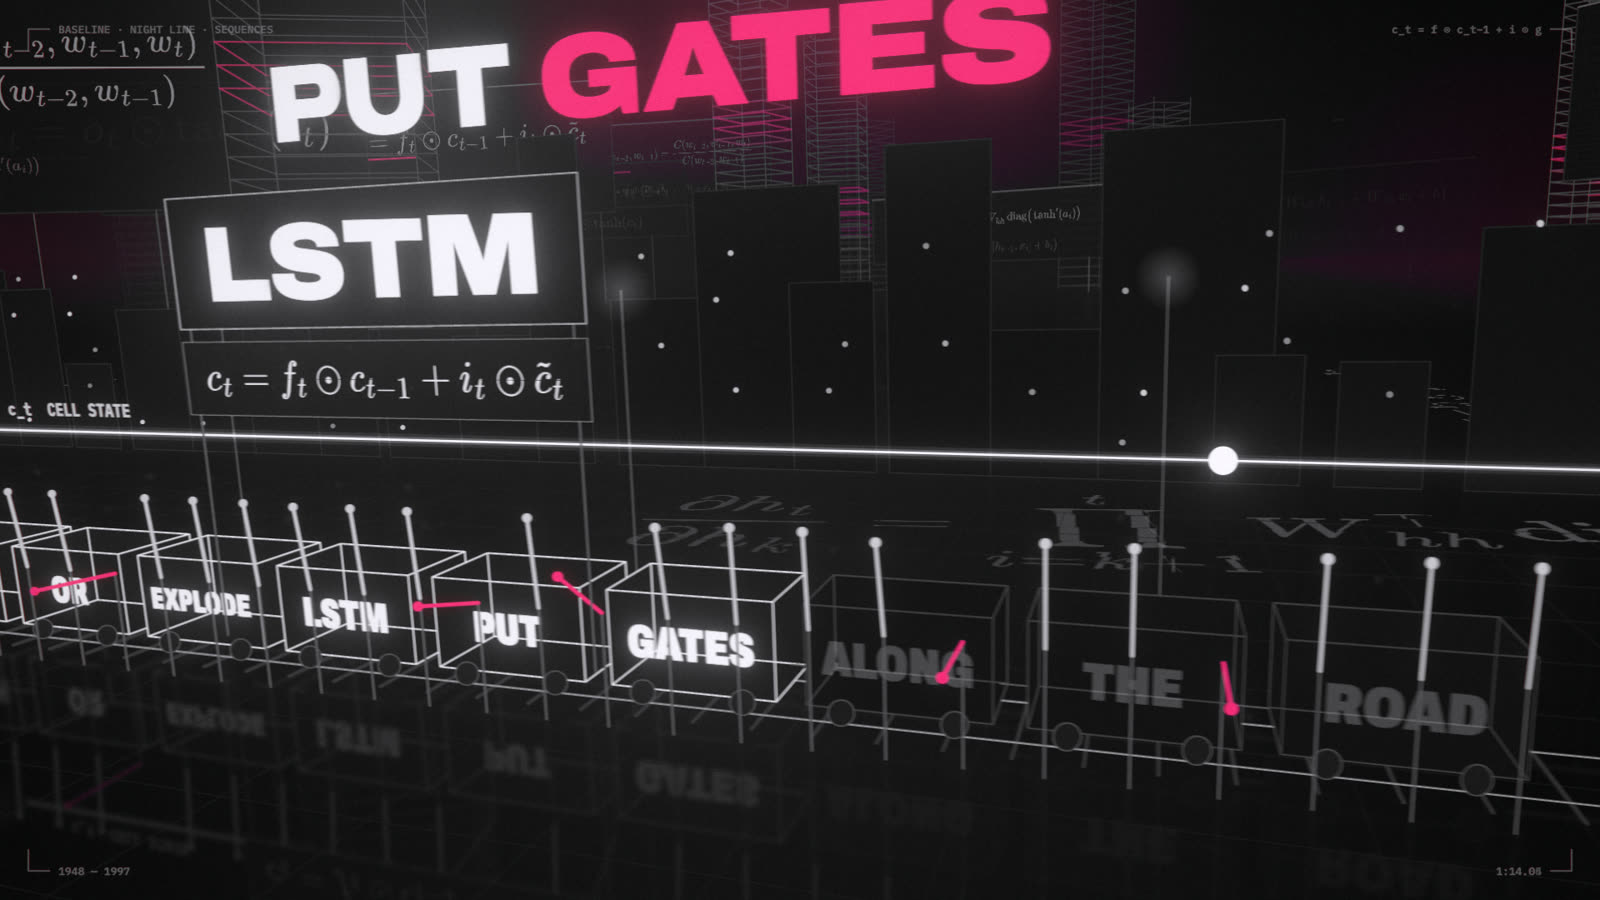

In [11]:
still(74.05)



## 2.5 Seq2seq squeezes a sentence through a bottleneck; attention looks back
Translation maps one sequence to another of a different length. **Seq2seq** (Sutskever et al., 2014) uses two RNNs. An *encoder* reads the whole input into one fixed-size vector, and a *decoder* generates the output from that vector alone. That vector is the **bottleneck**: a 5-word sentence and a 50-word sentence must fit in the same space.

**Attention** (Bahdanau et al., 2014) removes it. At every output step the decoder compares its state to *every* encoder state, turns the similarities into weights with a softmax, and reads a weighted average of them:

$$\alpha_{tj} = \text{softmax}_j(s_t \cdot h_j) \qquad \text{context}_t = \sum_j \alpha_{tj}\,h_j$$

Test task: **reverse a string of digits**. It's trivial for code, and a good stress test for memory.

> **Predict first.** Both models train on strings of 4–24 digits. Which one's accuracy will fall as strings get longer, and roughly where?



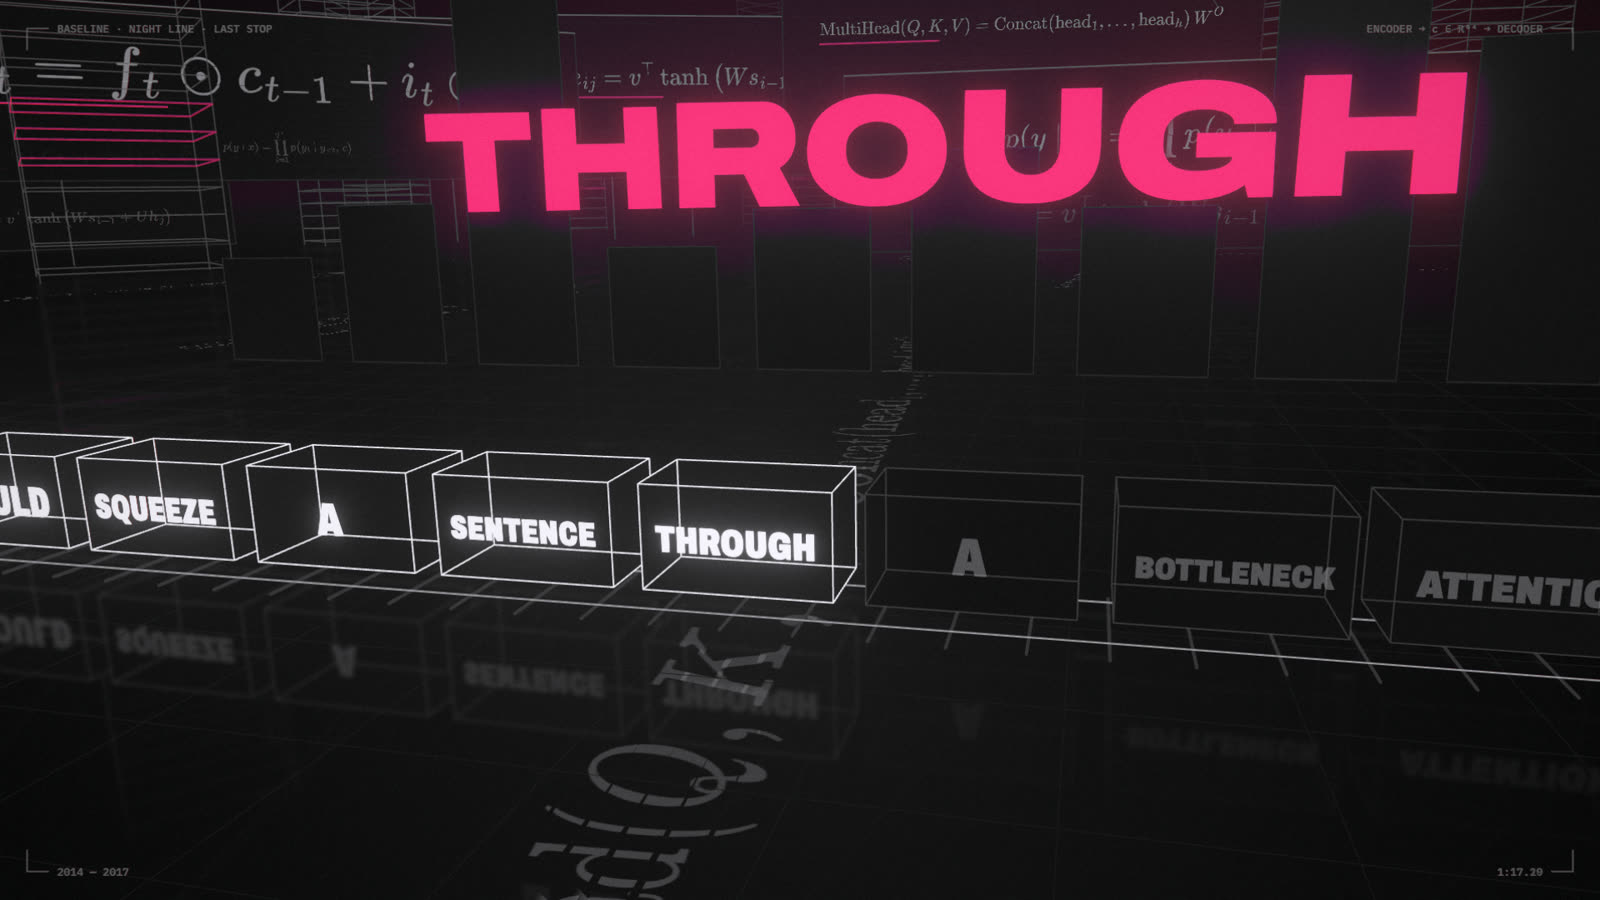

In [12]:
still(77.2)



seq2seq (bottleneck): 40.67s


seq2seq + attention: 42.50s


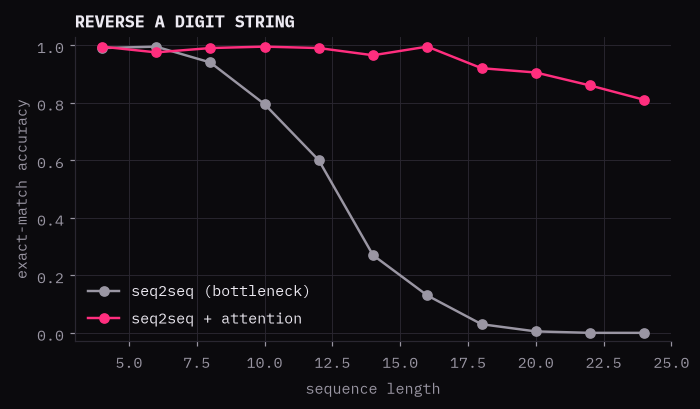

In [13]:
V_DIG, BOS, MAXLEN = 12, 10, 24                 # tokens 0-9 digits, 10 = start, 11 = pad

def reverse_batch(B, lo=4, hi=MAXLEN):
    n = torch.randint(lo, hi + 1, (B,))
    src = torch.full((B, hi), 11); tgt = torch.full((B, hi), 11)
    for b in range(B):
        d = torch.randint(0, 10, (n[b],)); src[b, :n[b]] = d; tgt[b, :n[b]] = d.flip(0)
    return src, tgt, n

class Seq2Seq(nn.Module):
    def __init__(self, hidden=128, attention=False):
        super().__init__()
        self.attention = attention
        self.emb = nn.Embedding(V_DIG, 32)
        self.enc = nn.GRU(32, hidden, batch_first=True)
        self.dec = nn.GRU(32, hidden, batch_first=True)
        self.out = nn.Linear(hidden * (2 if attention else 1), V_DIG)
    def forward(self, src, tgt_in):
        H, h = self.enc(self.emb(src))                       # H: all encoder states; h: the final one (the bottleneck)
        S, _ = self.dec(self.emb(tgt_in), h)
        if not self.attention:
            return self.out(S), None
        scores = S @ H.transpose(1, 2)                        # (B, T_out, T_in)
        scores = scores.masked_fill((src == 11).unsqueeze(1), -1e9)
        alpha = scores.softmax(-1)
        return self.out(torch.cat([S, alpha @ H], -1)), alpha

def shift(tgt):
    return torch.cat([torch.full((len(tgt), 1), BOS, device=tgt.device), tgt[:, :-1]], 1)

models = {}
for attention in (False, True):
    seed(0); m = Seq2Seq(attention=attention).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 3e-3)
    with timer(f"seq2seq {'+ attention' if attention else '(bottleneck)'}:"):
        for step in range(1500):
            src, tgt, _ = reverse_batch(64)
            logits, _ = m(src.to(DEVICE), shift(tgt).to(DEVICE))
            loss = F.cross_entropy(logits.flatten(0, 1), tgt.to(DEVICE).flatten(), ignore_index=11)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1); opt.step()
    models[attention] = m

@torch.no_grad()
def decode(m, src, n):                                        # greedy, one token at a time
    tgt = torch.full((len(src), MAXLEN), 11, device=DEVICE)
    for t in range(n):
        logits, alpha = m(src, shift(tgt))
        tgt[:, t] = logits[:, t].argmax(-1)
    return tgt[:, :n], alpha

lengths = list(range(4, MAXLEN + 1, 2)); acc = {False: [], True: []}
for n in lengths:
    src, tgt, _ = reverse_batch(200, n, n)
    src = torch.cat([src[:, :n], torch.full((200, MAXLEN - n), 11)], 1).to(DEVICE)
    for att in (False, True):
        pred, _ = decode(models[att], src, n)
        acc[att].append((pred.cpu() == tgt[:, :n]).all(1).float().mean().item())

fig, ax = plt.subplots()
ax.plot(lengths, acc[False], 'o-', c=ASH, label='seq2seq (bottleneck)')
ax.plot(lengths, acc[True], 'o-', c=MAG, label='seq2seq + attention')
ax.set(xlabel='sequence length', ylabel='exact-match accuracy', title='REVERSE A DIGIT STRING', ylim=(-0.03, 1.03)); ax.legend();



The bottleneck model degrades as the input gets longer. The attention model doesn't, because it never has to fit the whole sequence into one vector. Here is what it looks at while reversing one string:



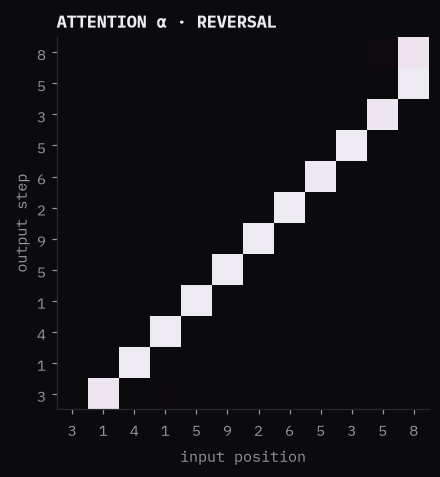

In [14]:
digits = torch.tensor([[3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5, 8] + [11] * (MAXLEN - 12)], device=DEVICE)
pred, alpha = decode(models[True], digits, 12)
fig, ax = plt.subplots(figsize=(4.4, 4.4))
ax.imshow(alpha[0, :12, :12].cpu(), cmap='baseline'); ax.grid(False)
ax.set(xticks=range(12), yticks=range(12), xlabel='input position', ylabel='output step', title='ATTENTION α · REVERSAL')
ax.set_xticklabels(digits[0, :12].tolist()); ax.set_yticklabels(pred[0].tolist());



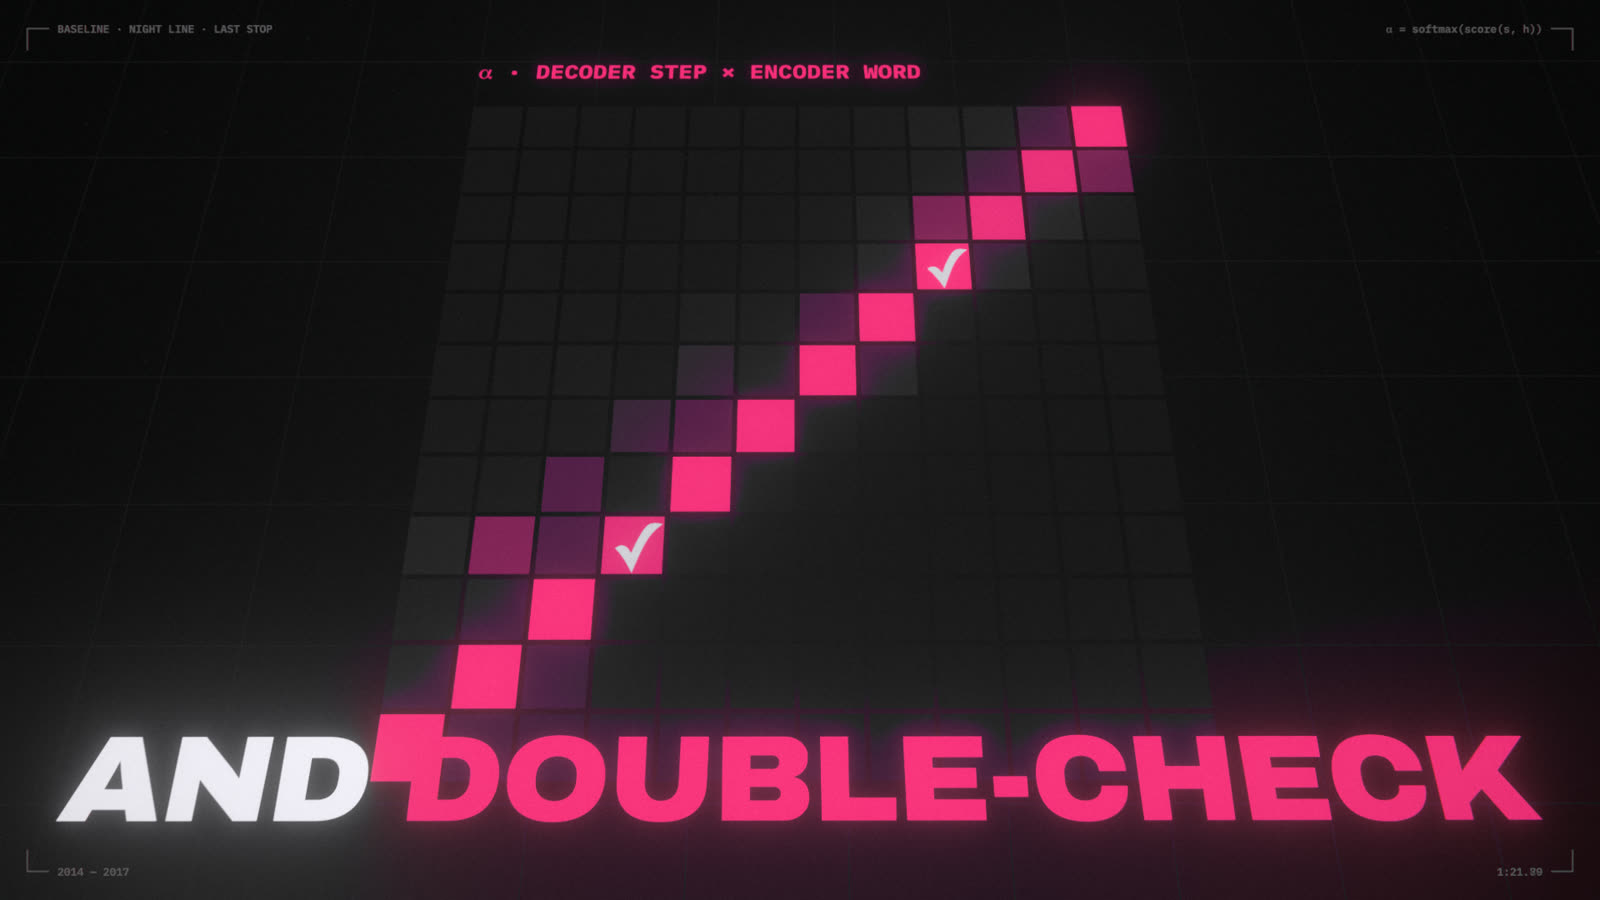

In [15]:
still(81.8)



### Your turn: attention for one query
Write attention for a single query vector `q` (d numbers) over T keys `K` (T × d) and values `V` (T × v): score each key with a dot product scaled by 1/√d, softmax the scores into weights, and return the weighted sum of the values. This is the "soft dictionary lookup" in about three lines, and the check compares it with PyTorch's built-in attention.



In [16]:
def attention_row(q, K, V):
    """q: (d,), K: (T, d), V: (T, v) tensors. Return the attended value, shape (v,)."""
    raise NotImplementedError        # your code here

check('attention_row', attention_row)



⏳ attention_row: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


## 2.6 The Transformer: attention is all you need (2017)
If attention does the important work, do we need the recurrence at all? The **Transformer** (Vaswani et al., 2017) drops it. Each layer is **self-attention**, where every position attends to every other position in the same sequence, followed by a small per-position MLP. There's no sequential dependency between positions, so a GPU computes all of them **in parallel**. That parallelism is why it scaled when RNNs couldn't.

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Q, K and V are three learned linear projections of the input. A **decoder-only** language model like GPT adds a *causal mask*, so position t can only attend to positions ≤ t: it predicts the next token from the past. `TinyGPT` in `blcourse.py` is about 50 lines; read it.



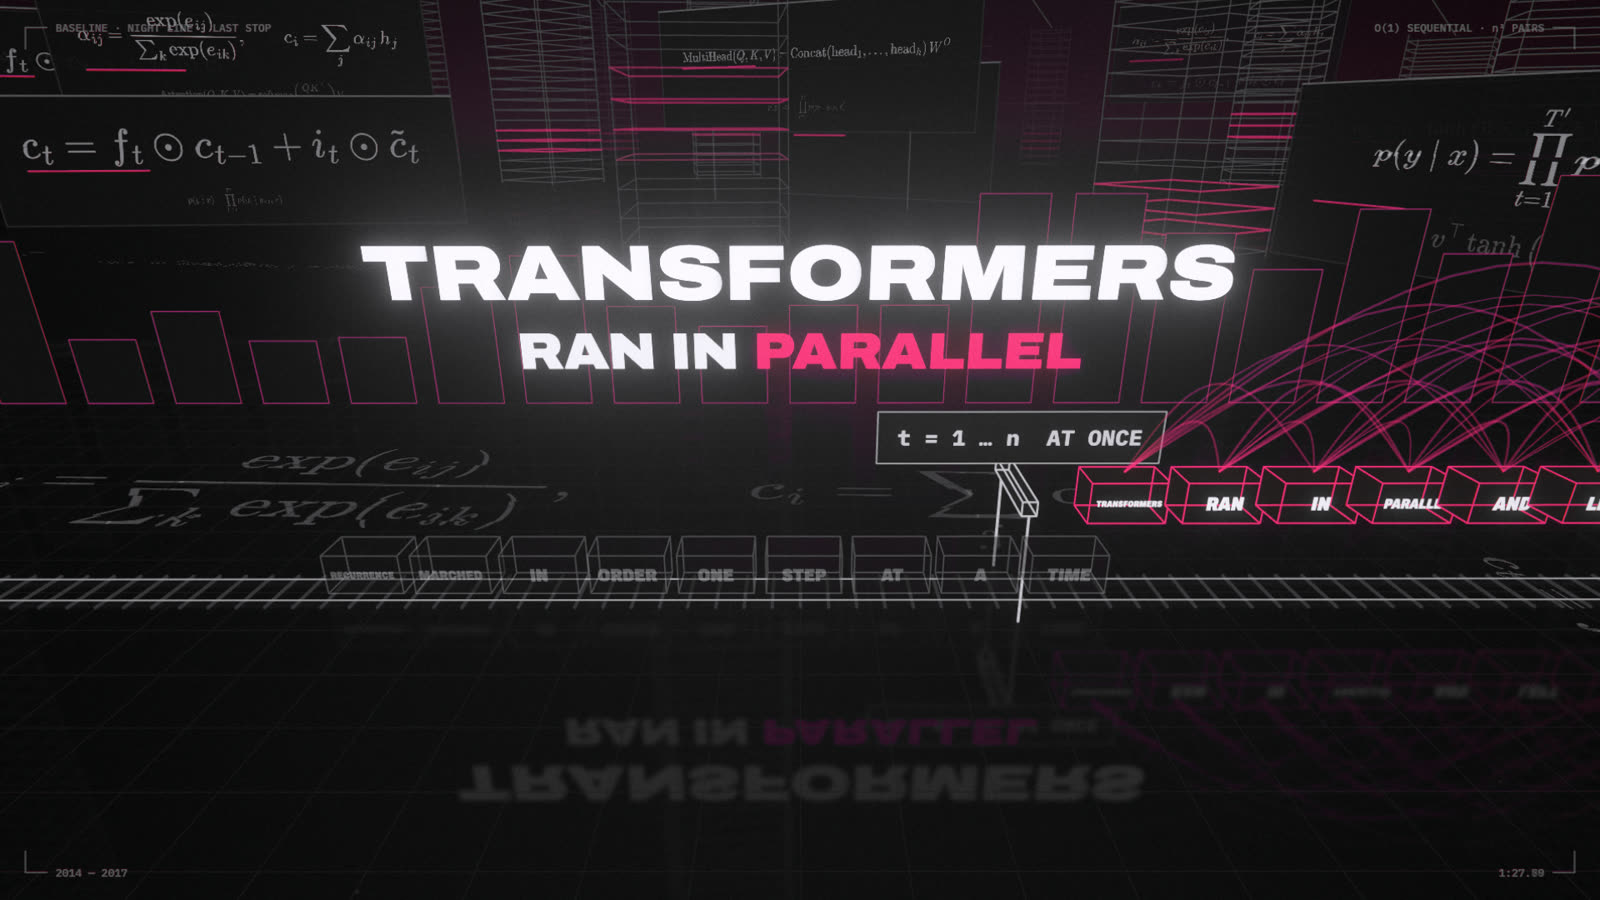

In [17]:
still(87.7)

# > **Predict first.** On the `laptop` tier the LSTM above reached its validation loss with about 0.35M parameters. Will this Transformer, with about 0.8M, beat it clearly, tie, or lose?



In [18]:
G = CFG['gpt']
seed(0); gpt = TinyGPT(data.vocab, **G)
print(f'TinyGPT: {n_params(gpt):,} parameters')
gpt_hist = train_lm(gpt, data, G['steps'], G['block'], G['batch'], label='GPT')
SCORES['Transformer'] = eval_loss(gpt, data, G['block'], iters=50)['val']



TinyGPT: 824,320 parameters


GPT step   250  train 2.100  val 2.160  (6s)


GPT step   500  train 1.717  val 1.827  (12s)


GPT step   750  train 1.544  val 1.668  (18s)


GPT step  1000  train 1.455  val 1.591  (24s)


GPT step  1250  train 1.385  val 1.549  (30s)


GPT step  1500  train 1.376  val 1.542  (36s)


In [19]:
ctx = torch.tensor([data.encode('ROMEO:\n')], device=DEVICE)
print(data.decode(gpt.generate(ctx, 300)[0].tolist()))



ROMEO:
Well, shall melt thou hast their curse to be
Who out is thy heavy thoughts of it
Accept the weing no make so sweeter to bring me.

AUTOLYCUS:
I stamp, I lesse thee for change you, 'twas yet?

PERD OF Servant:
For your look; and my lord, as I dead
Have the oar-son a true on a touchied: I wear?

Serva


### Sampling and temperature
The model outputs a probability for every next character, and `generate` *samples* one from that distribution, appends it, and repeats. The `temperature` argument reshapes the distribution first: divide the logits by T before the softmax. T < 1 sharpens it toward the most likely character (safer, more repetitive); T > 1 flattens it (more varied, more mistakes). T → 0 means always taking the top choice, which is called greedy decoding.

### Your turn: temperature



In [20]:
def apply_temperature(logits, T):
    """logits: a 1-D tensor of scores. Return the probabilities after temperature T."""
    raise NotImplementedError        # your code here: one line

check('temperature', apply_temperature)



⏳ temperature: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


In [21]:
for T in (0.3, 1.5):
    seed(1)
    print(f'── temperature {T} ──')
    print(data.decode(gpt.generate(ctx, 160, temperature=T)[0].tolist()), '\n')



── temperature 0.3 ──


ROMEO:
I was not the country of the man of the world,
And the stay of the strike of the sena
That will be the speck of the stread of the way.

BUCKINGHAM:
Ay, thou sha 

── temperature 1.5 ──


ROMEO:
O, alancY take me conest-to tell have's?
The rithers: do oldmysours. This didsBoULESSdachve's dayDious is.

JUTUS COMyful-lazer?

3PSAPELBIO:
Wessufullly? slewi 



### The scoreboard
All models, the same validation text, the same unit. This is the module's own leaderboard.



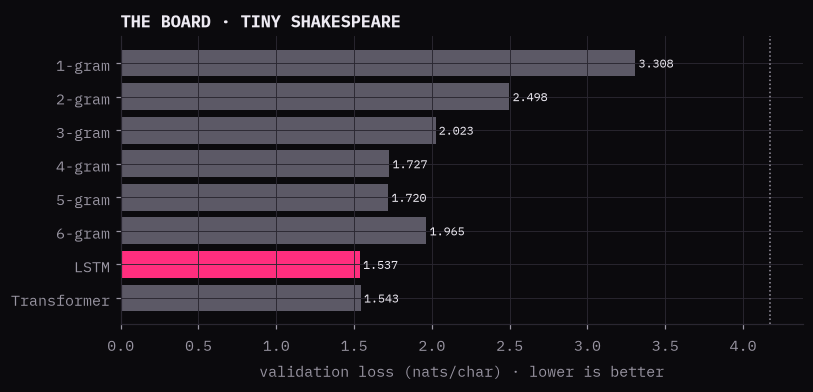

In [22]:
names = list(SCORES); vals = [SCORES[k] for k in names]
best = min(vals)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(names, vals, color=[MAG if v == best else GRAPHITE for v in vals])
for i, v in enumerate(vals):
    ax.text(v + 0.02, i, f'{v:.3f}', va='center', fontsize=8, color=BONE)
ax.invert_yaxis(); ax.set(xlabel='validation loss (nats/char) · lower is better', title='THE BOARD · TINY SHAKESPEARE')
ax.axvline(math.log(data.vocab), c=ASH, ls=':', lw=1);



On the `laptop` tier the LSTM and the Transformer often finish close together. At this size and training budget the Transformer has no big edge in modeling ability. Its edge is that it **parallelizes and scales**, which you'll measure in Module 5. Try the `mac-max`/`cuda` tiers and watch the gap open.

### What does a head look at?
Attention weights for the last layer's heads on one line of text. Each row is a position doing the looking. The upper triangle is empty because of the causal mask.



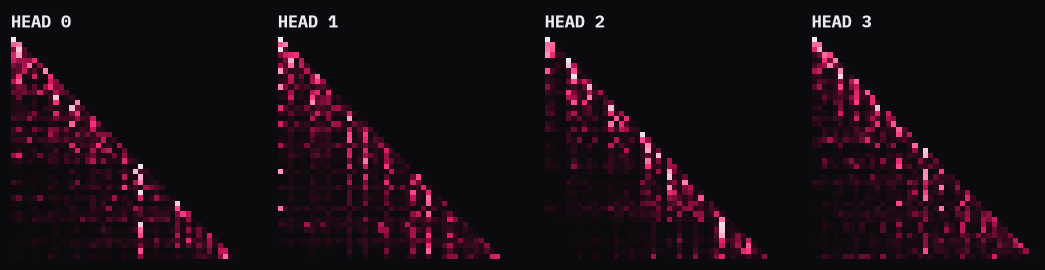

In [23]:
@torch.no_grad()
def attn_maps(model, s, layer=0):
    model.eval()
    x = model.embed(torch.tensor([data.encode(s)], device=DEVICE))
    for b in model.blocks[:layer]:
        x = b(x)
    return model.blocks[layer].attn_weights(x)[0].cpu()

s = 'To be, or not to be, that is the question:'
w = attn_maps(gpt, s, layer=len(gpt.blocks) - 1)
fig, axes = plt.subplots(1, w.shape[0], figsize=(3 * w.shape[0], 3.2))
for h_, ax in enumerate(np.atleast_1d(axes)):
    ax.imshow(w[h_] ** 0.5, cmap='baseline'); ax.set_title(f'HEAD {h_}'); ax.axis('off')



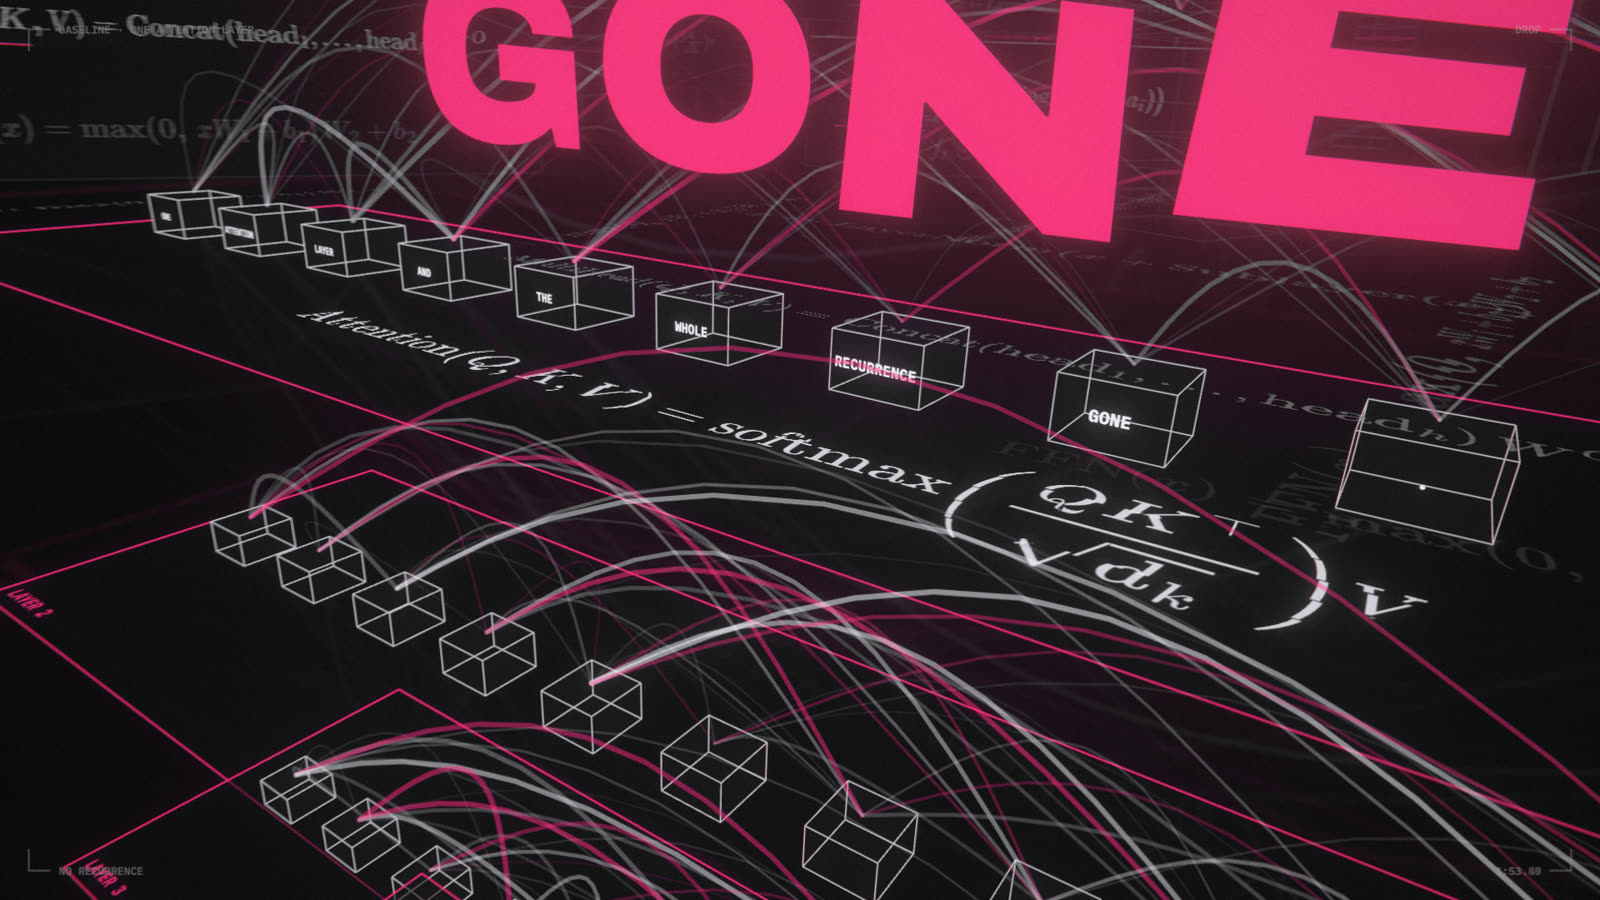

In [24]:
still(113.5)



## 2.7 BERT read both ways; decoder-only scaled up
**BERT** (2018) is a Transformer *encoder*. Every token attends to every other token, left and right, and it's trained by hiding 15% of the tokens behind `[MASK]` and predicting them. That made it excellent at *understanding* tasks (classification, search, extraction), but it can't generate text left to right.

A **decoder-only** model (GPT) uses a causal mask and predicts the next token. Scaled to 175B parameters (GPT-3, 2020), it handled most of BERT's tasks through prompting, and it could generate as well. The only architectural difference is the mask:



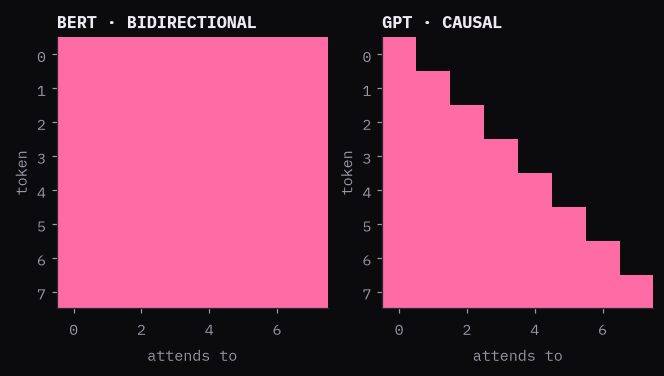

In [25]:
n = 8
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
for ax, (title, m) in zip(axes, [('BERT · BIDIRECTIONAL', np.ones((n, n))), ('GPT · CAUSAL', np.tril(np.ones((n, n))))]):
    ax.imshow(m, cmap='baseline', vmin=0, vmax=1.4); ax.set_title(title); ax.set(xlabel='attends to', ylabel='token'); ax.grid(False)



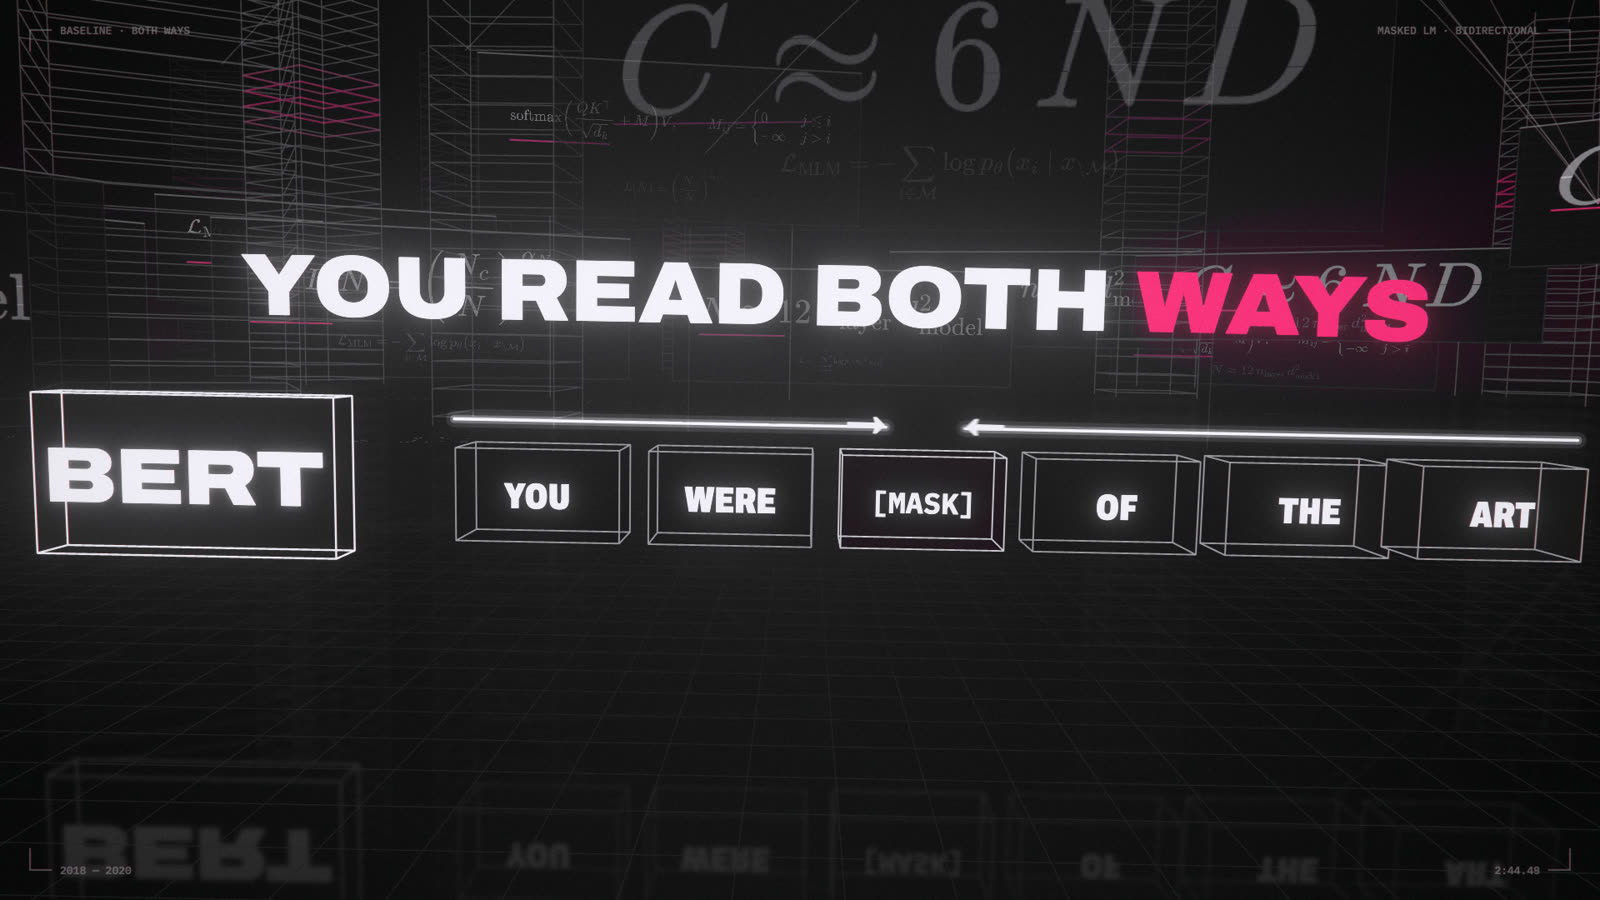

In [26]:
still(164.49)



Let's ask a real BERT (DistilBERT, a 260 MB download) to fill in the film's mask:



In [27]:
from transformers import pipeline
fill = pipeline('fill-mask', model='distilbert/distilbert-base-uncased', device=DEVICE)
for r in fill('you were [MASK] of the art, now you are just a baseline.', top_k=5):
    print(f"{r['score']:.3f}  {r['token_str']}")
del fill



0.132  part
0.093  master
0.084  masters
0.055  ignorant
0.046  fond


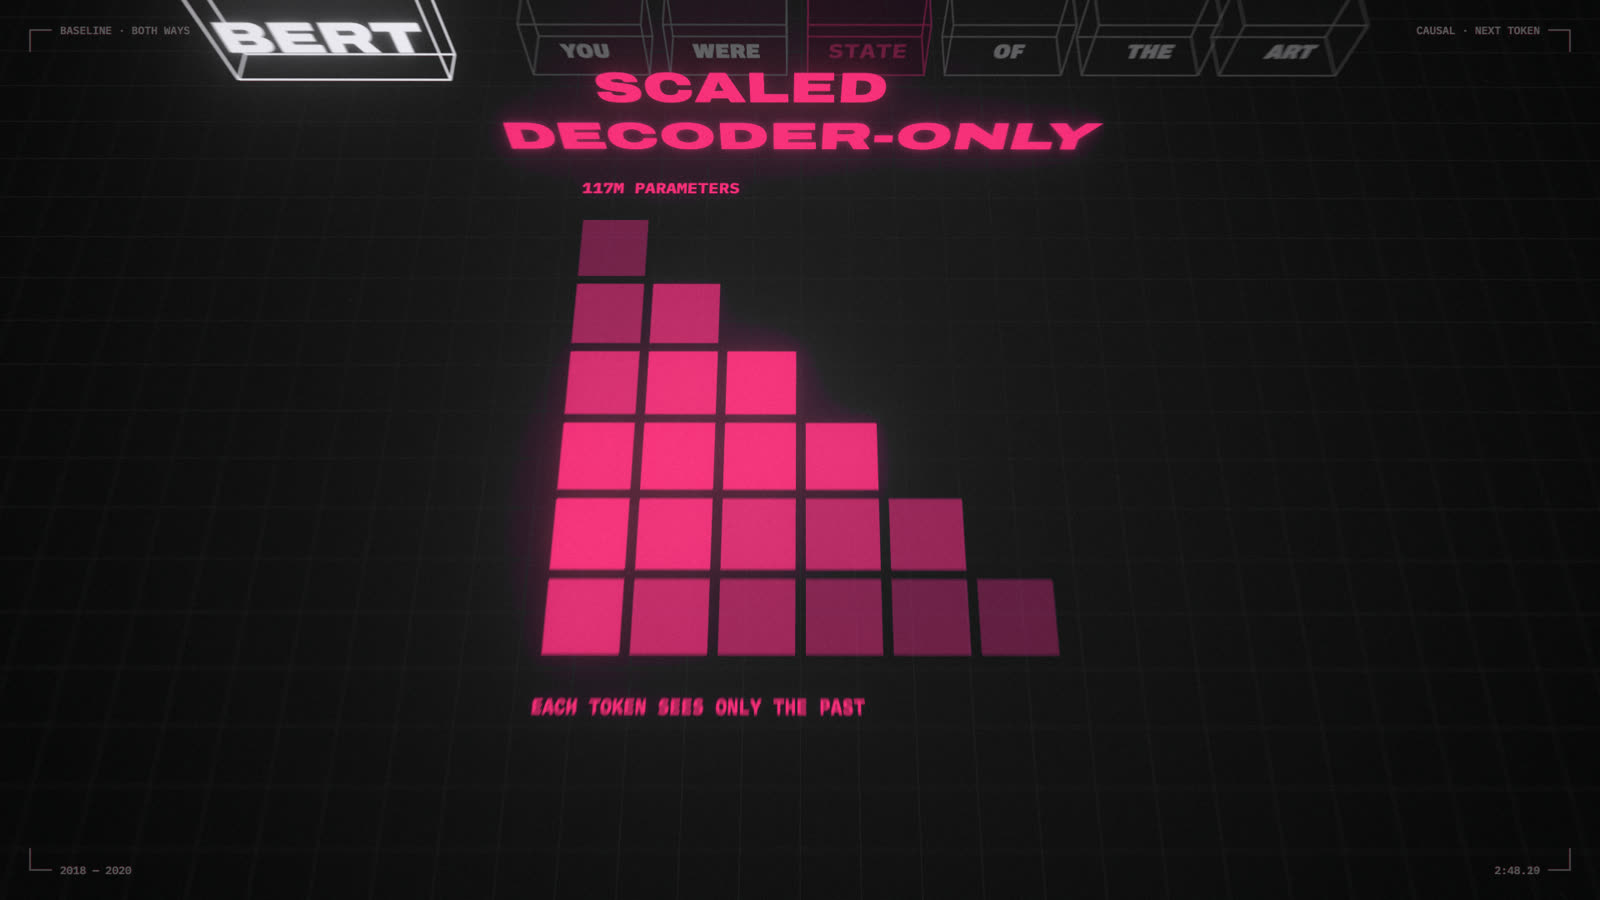

In [28]:
still(168.2)



BERT-style encoders are far from dead in practice. They're still the workhorse behind **embedding models** for search and retrieval. But "SOTA on GLUE" went to the decoders.



## 2.8 The parts list of a modern LLM
The Transformer you just built is the 2017 design. A few lines of Verse 3 each swap one of its parts, and today's LLMs (including the one you'll run in Module 4) use all of the swaps. Here is each one in a few lines of code.



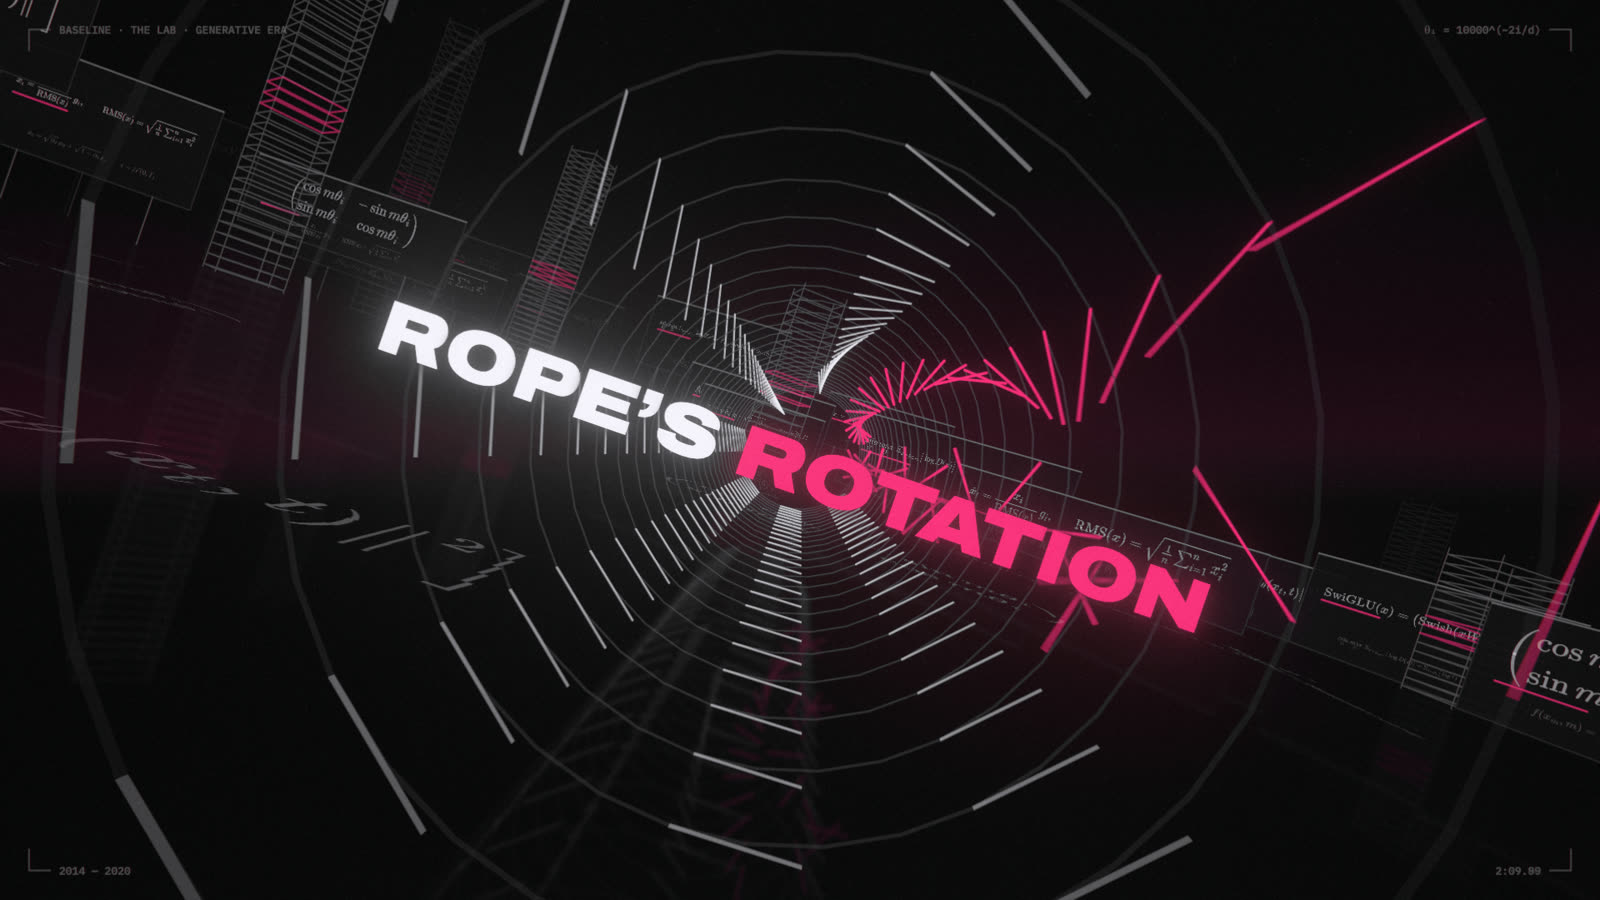

In [29]:
still(129.9)



**Positions: sinusoids → RoPE.** Attention is order-blind: shuffle the tokens and the weights shuffle with them. The original Transformer *added* a fixed sinusoidal vector to each token to mark its position. **RoPE** (Su et al., 2021) instead *rotates* the query and key vectors by an angle proportional to the position. The dot product of two rotated vectors depends only on the *difference* of their angles, so attention scores depend only on **relative** position. Let's check numerically:



In [30]:
def rope(x, pos, base=10000.0):
    d = x.shape[-1]; theta = base ** (-torch.arange(0, d, 2) / d)
    ang = pos * theta; c, s = ang.cos(), ang.sin()
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * c - x2 * s, x1 * s + x2 * c], -1).flatten(-2)

seed(0); q, k = torch.randn(64), torch.randn(64)
for m, n in [(5, 2), (105, 102), (1005, 1002), (7, 2)]:
    print(f'q at {m:4d}, k at {n:4d}  (m − n = {m - n}):  q·k = {rope(q, m) @ rope(k, n):+.5f}')



q at    5, k at    2  (m − n = 3):  q·k = -8.28110
q at  105, k at  102  (m − n = 3):  q·k = -8.28110
q at 1005, k at 1002  (m − n = 3):  q·k = -8.28106
q at    7, k at    2  (m − n = 5):  q·k = -8.99309


**Normalization: LayerNorm → RMSNorm.** Deep nets keep activations at a sane scale by normalizing them in every layer. LayerNorm subtracts the mean and divides by the standard deviation. RMSNorm (2019) skips the mean and divides by the root-mean-square. That's cheaper, and it works just as well in practice.

**Activation: ReLU → SwiGLU.** SwiGLU (Shazeer, 2020) multiplies two linear projections, one passed through Swish(x) = x·σ(x): `down(swish(gate(x)) * up(x))`. It's a learned gate inside the MLP.



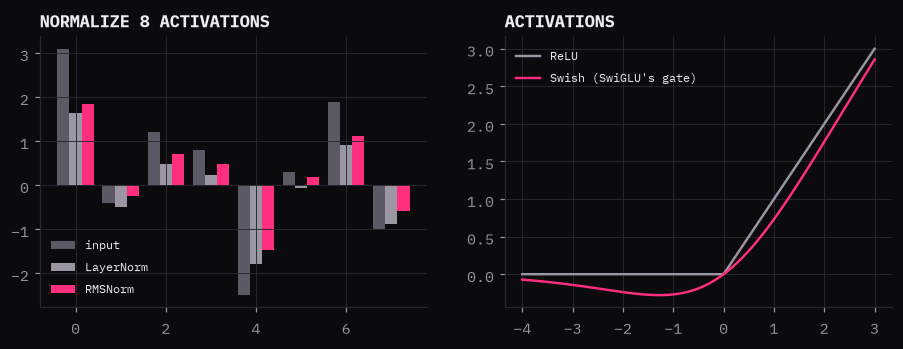

In [31]:
x = torch.tensor([3.1, -0.4, 1.2, 0.8, -2.5, 0.3, 1.9, -1.0])
ln = (x - x.mean()) / x.std(unbiased=False); rms = x / x.pow(2).mean().sqrt()
z = torch.linspace(-4, 3, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
i = np.arange(8)
a1.bar(i - 0.27, x, 0.27, color=GRAPHITE, label='input'); a1.bar(i, ln, 0.27, color=ASH, label='LayerNorm'); a1.bar(i + 0.27, rms, 0.27, color=MAG, label='RMSNorm')
a1.set_title('NORMALIZE 8 ACTIVATIONS'); a1.legend(fontsize=8)
a2.plot(z, torch.relu(z), c=ASH, label='ReLU'); a2.plot(z, z * torch.sigmoid(z), c=MAG, label='Swish (SwiGLU\'s gate)')
a2.set_title('ACTIVATIONS'); a2.legend(fontsize=8);



These aren't just textbook parts. Download the configuration of this course's LLM (a few KB) and you'll find every one of them:



In [32]:
from transformers import AutoConfig
cfg = AutoConfig.from_pretrained(CFG['llm'])
for k in ['model_type', 'num_hidden_layers', 'hidden_size', 'num_attention_heads', 'num_key_value_heads', 'intermediate_size',
          'hidden_act', 'rms_norm_eps', 'rope_theta', 'max_position_embeddings', 'vocab_size']:
    print(f'{k:>24}: {getattr(cfg, k, getattr(cfg, "rope_parameters", {}).get(k) if k == "rope_theta" else None)}')



              model_type: qwen2
       num_hidden_layers: 24
             hidden_size: 896
     num_attention_heads: 14
     num_key_value_heads: 2
       intermediate_size: 4864
              hidden_act: silu
            rms_norm_eps: 1e-06
              rope_theta: 1000000.0
 max_position_embeddings: 32768
              vocab_size: 151936


`hidden_act: silu` is Swish, used inside a SwiGLU MLP. `rms_norm_eps` means RMSNorm. `rope_theta` is RoPE's base frequency. Every block of this model is the verse's parts list.



### Checkpoint
1. Why does an n-gram model stop improving as n grows?
2. What goes wrong when you backprop through 64 steps of an RNN, and how do LSTM gates help?
3. What is the seq2seq bottleneck, and how does attention remove it?
4. Why is the Transformer easier to scale than an LSTM, even when they reach similar loss at small sizes?
5. BERT vs GPT: what's the one architectural difference, and what does each make easy?
6. RoPE makes the attention score between two tokens depend on what?

<details><summary>Answers</summary>

1. The table goes sparse: most long contexts in new text never appeared in training, so their counts say nothing. Counting also can't share what it learned between similar words.
2. The gradient is multiplied by roughly the same matrix at every step, so it shrinks toward 0 or blows up. The LSTM's cell state is updated by multiply-and-add through gates, so when the forget gate is near 1 the signal (and gradient) passes through almost unchanged.
3. The encoder must squeeze the whole input into one fixed-size vector, so long inputs lose detail. Attention lets the decoder look at every encoder state at every step and take a weighted blend, so nothing has to fit in one vector.
4. Every position is computed in parallel, with no step-by-step dependency, so training uses a GPU's thousands of cores and grows with more data and compute. An RNN must process tokens one after another.
5. The attention mask. BERT lets every token see every token (good for understanding: classification, search, embeddings). GPT's causal mask lets a token see only the past (good for generating text one token at a time).
6. Only on how far apart the two tokens are (m − n), not on where they sit.
</details>

**Next:** Module 3, generating data.